---
title: "Accessing the DestinE Digital Twins"
subtitle: "Which way of accessing DT data fits your needs? A case study demonstration."
author: "Author: Alejandro Fonseca (EUMETSAT/Starion)"
tags: [HDA, Polytope, Earth Data Hub, ECMWF, Digital Twin, Dask]
thumbnail: ../../img/EUMETSAT-icon.png
license: MIT
copyright: "© 2026 EUMETSAT"
---

# Accessing the DestinE Digital Twins

This notebook answers one question: what is the best way to access the DestinE Digital Twins (DTs) for my needs?

It is organised as a series of practical questions. Each one describes a use case, shows an access method with code and a figure, and explains where that method fits and where it does not. The examples cover the Climate DT, the Extremes DT and the On-Demand Extremes DT, for a single point, a small area or a large region.

The questions are numbered Q0 to Q12 and the access methods M1 to M4. Q2 to Q12 are eleven use cases, grouped by task and by Digital Twin, and each one uses the method that suits it best. The notebook ends with a diagram that helps you choose a method.

(access_dts.ipynb-Contents)=
### Contents

- **Objective:** help you choose the route to DT data that fits your task, with a working example for each one
- **Data Sources:** the Climate DT (generations 1 and 2, storylines, nextGEMS), the Extremes DT and the On-Demand Extremes DT, reached through the DestinE Data Lake. See the [Climate DT page](https://destine.ecmwf.int/climate-change-adaptation-digital-twin-climate-dt/).
- **Methods:** the HDA REST API, the Polytope service, Earth Data Hub cubes found through HDA, and Dask. Native HEALPix values are read with `healpy`, GRIB files with `earthkit-data`, and regridding is done with `earthkit-geo`.
- **Prerequisites:** a DestinE user account with upgraded access to the Digital Twin data (see [Prerequisites](#access_dts.ipynb-Prerequisites)).
- **Expected Output:** one summary line and one figure for each question, and a final diagram for choosing a route.

(access_dts.ipynb-Prerequisites)=
## Prerequisites

- Python packages: `numpy`, `pandas`, `xarray`, `zarr`, `dask`, `requests`, `matplotlib`, `cartopy`, `earthkit-data`, `earthkit-geo`, `healpy`, `aiohttp` and `destinelab`.
- On the DEDL JupyterHub, the Python DEDL kernel has all of them except `healpy`. The next cell installs it. If the import fails afterwards, restart the kernel and run the notebook again from the imports.

In [ ]:
%pip install --quiet healpy
import site, sys
sys.path.append(site.getusersitepackages())  # pip may install in your user folder, which a running kernel does not see until it restarts

## Imports

In [1]:
import getpass, hashlib, json, os, re, tempfile, time
from pathlib import Path
from urllib.parse import urljoin

import destinelab as deauth
import earthkit.data as ekd
import earthkit.geo as ekg
import healpy as hp
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import requests
import xarray as xr
from cartopy import crs as ccrs, feature as cfeature
from matplotlib.collections import PolyCollection
from requests.adapters import HTTPAdapter, Retry

## Helpers

The questions below share a few short functions, in three groups.

- Access and downloads: `report` prints the summary line of each question, `retry` repeats a read when the download host fails, `hda_order` orders from HDA and downloads the file, `open_cube` opens an Earth Data Hub cube, and `polytope_headers` and `polytope_retrieve` talk to Polytope directly.
- Requests and answers: `climate_body` and `extremes_body` build the HDA searches, and `covjson_points` and `covjson_series` read the answers.
- Maps: `base_map`, `plot_cells` and `plot_grid`.

Downloads go to your temporary folder, so running a cell twice does not order twice. Set the environment variable `DTS_CACHE` to use another folder.

### Access and downloads

In [2]:
STAC = "https://hda.data.destination-earth.eu/stac/v2"
POLYTOPE = "https://polytope.mn5.apps.dte.destination-earth.eu"  # Climate DT, IFS-NEMO model
LUMI = "https://polytope.lumi.apps.dte.destination-earth.eu"  # Extremes DT, On-Demand Extremes DT and the ICON model
CACHE = Path(os.environ.get("DTS_CACHE", tempfile.gettempdir()))  # downloads go here, so a second run does not order again
CACHE.mkdir(parents=True, exist_ok=True)

http = requests.Session()  # raises on errors and retries a finished order that answers 404 or 502 at first
http.hooks["response"] = [lambda r, *args, **kwargs: r.raise_for_status()]
http.mount("https://", HTTPAdapter(max_retries=Retry(total=5, backoff_factor=3, status_forcelist=[404, 502])))


def report(tag, text, size=None, t0=None):
    """Print one summary line, with the same format in every question."""
    size = size and (f"{size / 1e6:.1f} MB" if size > 1e6 else f"{size / 1e3:.0f} KB")
    print(f"[{tag}] " + " | ".join(p for p in [text, size, t0 and f"{time.time() - t0:.0f} s"] if p))


def retry(task, tries=5):
    """Run task(), and run it again after a pause if the download host fails."""
    for _ in range(tries - 1):
        try:
            return task()
        except Exception:
            time.sleep(10)
    return task()


def hda_order(body, headers):
    """Search, order, wait and download from HDA. Returns the path of the file, which is kept in CACHE."""
    path = CACHE / hashlib.sha1(json.dumps(body, sort_keys=True).encode()).hexdigest()[:10]
    if not path.exists():
        link = next(l for l in http.post(f"{STAC}/search", headers=headers, json=body).json()["features"][0]["links"] if l["rel"] == "retrieve")
        order = http.post(link["href"], headers=headers, json=link.get("body")).json()
        while order["properties"]["order:status"] not in ("succeeded", "failed"):
            time.sleep(3)
            order = http.get(f"{STAC}/collections/{body['collections'][0]}/items/{order['id']}", headers=headers).json()
        assert order["properties"]["order:status"] == "succeeded", "HDA order failed"
        path.write_bytes(http.get(order["assets"]["downloadLink"]["href"], headers=headers).content)
    return path


def open_cube(collection, headers):
    """Open an Earth Data Hub cube lazily. HDA gives the address of the Zarr store."""
    item = http.get(f"{STAC}/collections/{collection}/items", headers=headers).json()["features"][0]
    href = next(a["href"] for a in item["assets"].values() if ".zarr" in a["href"])
    return retry(lambda: xr.open_dataset(href, engine="zarr", chunks={}, zarr_format=3,
                                         storage_options={"client_kwargs": {"trust_env": False, "headers": headers}}))


def polytope_headers(user, password):
    """Log in to DestinE and return the headers that Polytope expects (it has its own token)."""
    iam = "https://auth.destine.eu/realms/desp/protocol/openid-connect"
    app = {"client_id": "polytope-api-public", "redirect_uri": f"{LUMI}/"}
    session = requests.Session()
    page = session.get(f"{iam}/auth", params={**app, "scope": "openid offline_access", "response_type": "code"})
    form = re.search(r'action="([^"]+)"', page.text).group(1).replace("&amp;", "&")
    login = session.post(form, data={"username": user, "password": password}, allow_redirects=False)
    code = re.search(r"code=([^&]+)", login.headers["Location"]).group(1)
    token = requests.post(f"{iam}/token", data={**app, "code": code, "grant_type": "authorization_code", "scope": ""}).json()["refresh_token"]
    return {"Authorization": f"Bearer {token}"}


def polytope_retrieve(request, headers, address=POLYTOPE):
    """Send a request to Polytope, wait until it is ready and return the bytes."""
    r = http.post(f"{address}/api/v1/requests/destination-earth", headers=headers, json={"verb": "retrieve", "request": json.dumps(request)})
    while r.status_code == 202:
        time.sleep(5)
        r = http.get(urljoin(r.url, r.headers["Location"]), headers=headers)
    return r.content

### Requests and answers

In [3]:
EXTREMES = "EO.ECMWF.DAT.DT_EXTREMES"
G2 = "EO.ECMWF.DAT.D1.DT_CLIMATE.G2.PROJECTIONS_SSP3-7.0_IFS-NEMO.R1"  # Climate DT, generation 2
POLYTOPE_CLIMATE = {"class": "d1", "dataset": "climate-dt", "activity": "projections", "experiment": "SSP3-7.0", "generation": "2",
                    "model": "IFS-NEMO", "realization": "1", "expver": "0001", "type": "fc", "stream": "clte",
                    "date": "20300715", "time": "1200"}  # the same hour as the HDA examples


def climate_body(params, levels=None, levtype="sfc", resolution="high", datetime="2030-07-15T12:00:00Z", hours=("1200",)):
    """HDA search for the Climate DT (generation 2, SSP3-7.0, IFS-NEMO). params and levels are lists of codes."""
    query = {"ecmwf:resolution": {"eq": resolution}, "ecmwf:stream": {"eq": "clte"}, "ecmwf:levtype": {"eq": levtype},
             "ecmwf:time": {"eq": list(hours)}, "ecmwf:param": {"eq": params}}
    if levels:
        query["ecmwf:levelist"] = {"eq": levels}
    return {"collections": [G2], "datetime": datetime, "query": query}


def extremes_body(param, step="6"):
    """HDA search for the latest forecast (00 UTC) of the Extremes DT. Returns the body and the forecast date."""
    day = http.get(f"{STAC}/collections/{EXTREMES}/queryables").json()["properties"]["ecmwf:date"]["enum"][-1]  # latest date available now
    query = {"ecmwf:type": {"eq": "fc"}, "ecmwf:levtype": {"eq": "sfc"}, "ecmwf:stream": {"eq": "oper"}, "ecmwf:param": {"eq": [param]},
             "ecmwf:step": {"eq": [step]}, "ecmwf:time": {"eq": ["0000"]}}
    return {"collections": [EXTREMES], "datetime": f"{day[:4]}-{day[4:6]}-{day[6:]}T00:00:00Z", "query": query}, day


def covjson_points(path):
    """Latitude, longitude and values of a CovJSON answer made of cells (box, polygon or route)."""
    cov = json.loads(path.read_text())["coverages"][0]
    cells = np.array(cov["domain"]["axes"]["composite"]["values"])  # every row ends with [lat, lon, 0]
    return cells[:, -3], cells[:, -2], np.array(next(iter(cov["ranges"].values()))["values"])


def covjson_series(path):
    """Values of a CovJSON time series as a pandas Series. The cell that answered is kept in .attrs."""
    cov = json.loads(path.read_text())["coverages"][0]
    axes = cov["domain"]["axes"]
    series = pd.Series(next(iter(cov["ranges"].values()))["values"], index=pd.to_datetime(axes["t"]["values"]))
    series.attrs = {"lat": axes["latitude"]["values"][0], "lon": axes["longitude"]["values"][0]}
    return series

### Maps

In [4]:
def base_map(extent, ax=None, pad=0.1, outline=None, marks=None):
    """Map of extent = [west, east, south, north] with land, sea, coastlines and borders, and lakes and rivers for small areas.
    outline is a line of (lon, lat) points, marks a dict of named (lon, lat)."""
    west, east, south, north = extent
    p = pad * max(east - west, north - south)
    ax = ax or plt.subplots(figsize=(7, 5), subplot_kw={"projection": ccrs.PlateCarree()})[1]
    if east - west > 359:
        ax.set_global()
    else:
        ax.set_extent([west - p, east + p, south - p, north + p], crs=ccrs.PlateCarree())
    scale = "10m" if east - west < 5 else "50m"  # more detail for small areas
    ax.add_feature(cfeature.LAND.with_scale(scale), facecolor="0.92", zorder=0)
    ax.add_feature(cfeature.OCEAN.with_scale(scale), facecolor="#dceaf5", zorder=0)
    ax.add_feature(cfeature.COASTLINE.with_scale(scale), lw=0.8, zorder=3)
    ax.add_feature(cfeature.BORDERS.with_scale(scale), ls="--", lw=0.5, zorder=3)
    if scale == "10m":
        ax.add_feature(cfeature.LAKES.with_scale(scale), fc="#dceaf5", ec="#7aa6c8", lw=0.4, zorder=1)
        ax.add_feature(cfeature.RIVERS.with_scale(scale), ec="#7aa6c8", lw=0.6, zorder=1)
    ax.gridlines(draw_labels={"bottom": "x", "left": "y"}, ls=":")
    if outline:
        ax.plot(*zip(*outline), "k--", lw=1, transform=ccrs.PlateCarree(), zorder=4)
    for name, (x, y) in (marks or {}).items():
        ax.plot(x, y, "k*", ms=7, transform=ccrs.PlateCarree(), zorder=4)
        ax.annotate(name, (x, y), xytext=(5, 5), textcoords="offset points", fontweight="bold", bbox={"fc": "white", "alpha": 0.7, "ec": "none", "pad": 1})
    return ax


def plot_grid(data, title, label, ax=None, vmin=None, vmax=None, **kw):
    """Map of a regular grid. data is an xarray DataArray with latitude and longitude. kw goes to base_map."""
    lon, lat = data.longitude.values, data.latitude.values
    half = abs(lon[1] - lon[0]) / 2  # the grid points are the centres of the cells
    ax = base_map([lon.min() - half, lon.max() + half, lat.min() - half, lat.max() + half], ax, **{"pad": 0, **kw})
    data.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), zorder=2, vmin=vmin, vmax=vmax, cbar_kwargs={"label": label, "shrink": 0.8})
    ax.set_title(title, fontsize=10)


def plot_cells(lat, lon, values, nside, title, label, ax=None, vmin=None, vmax=None, **kw):
    """Map of HEALPix cells drawn with their real shape. kw goes to base_map (pad, outline, marks)."""
    corners = hp.boundaries(nside, hp.ang2pix(nside, lon, lat, nest=True, lonlat=True), nest=True)  # x, y, z of the four corners of every cell
    x, y = hp.vec2ang(corners.transpose(0, 2, 1).reshape(-1, 3), lonlat=True)
    shapes = np.stack([(x + 180) % 360 - 180, y], -1).reshape(-1, 4, 2)  # cells, corners, (lon, lat)
    ax = base_map([lon.min(), lon.max(), lat.min(), lat.max()], ax, **kw)
    drawn = ax.add_collection(PolyCollection(shapes, array=values, clim=(vmin, vmax), edgecolors="face", linewidths=0.5,
                                             transform=ccrs.PlateCarree(), zorder=2))
    ax.set_title(title, fontsize=10)
    plt.colorbar(drawn, ax=ax, label=label, shrink=0.8)

## Getting started

### Q0. Which credentials do I need?

**Situation:** you have never requested a DestinE service from code and want to know what to set up first.

**Short answer:** a DestinE Platform (DESP) account with upgraded access. The same user and password work for HDA, Polytope and Earth Data Hub.

**Why this route:** one login covers every route in Q1. The cell below logs in to HDA and asks the service whether your account can read Digital Twin data.

**Limitations:** keep your password out of the notebook. The cell reads the environment variables `DESP_USERNAME` and `DESP_PASSWORD` and asks for them only if they are missing.

In [5]:
t0 = time.time()
user = os.environ.get("DESP_USERNAME") or input("DESP username: ")
password = os.environ.get("DESP_PASSWORD") or getpass.getpass("DESP password: ")

auth = deauth.AuthHandler(user, password)
token = auth.get_token()
headers = {"Authorization": f"Bearer {token}"}
report("Q0 | login", f"token received: {bool(token)} | DT access allowed: {auth.is_DTaccess_allowed(token)}", t0=t0)

[Q0 | login] token received: True | DT access allowed: True | 1 s


If `DT access allowed` is `False`, your account has no upgraded access yet. Request it in My DataLake Services before you continue.

### Q1. What are my options?

**Situation:** you know which Digital Twin variable you want and need to choose how to get it.

**Short answer:** four routes, all with the same DESP login. Pick the one that matches the shape of the result you need.

| Mechanism (M) | You send | You get | Use it for | Considerations |
|---|---|---|---|---|
| **M1** Full field (HDA order) | A search and an order | The global field on the native grid, as GRIB | The whole globe, exact model values | The heaviest download. You crop and regrid it yourself |
| **M2** Extract on the server (HDA or Polytope) | The same request plus a shape: box, polygon, point, route or profile | Only your cells, native values, as CovJSON | A point, route, profile or small area | One shape per request, a queue, and CovJSON to convert |
| **M3** Regular grid for an area (Polytope) | A grid size and an area | A small GRIB on a regular grid | An area at the resolution you choose | A different address and token. The server interpolates |
| **M4** Earth Data Hub cube (Zarr, found through HDA) | Nothing to queue. You open the store | A lazy xarray dataset, decades long | Long time series and multi-year statistics | Climate DT generation 2 only, fixed grids, 500,000 chunk reads per month |

**Why start with this table?** Each question that follows takes one use case and demonstrates one of these methods (M1 to M4).

## By task

### Q2. How do I get a long time series at one location?

**Situation:** you want to see how precipitation at Rome changes from year to year until 2049.

**Short answer:** M4. Open the Earth Data Hub (EDH) cube and select the grid cell nearest to Rome. Use the cube that ends in `HOURLY_HIGH_TIMESERIES`: it is stored in long blocks of time, so one point needs few reads.

**Why this route:** there is no queue and no download step. 35 years of hourly values for one point come from 48 chunk reads, and the result is about 1 MB.

**Limitations:** the cube exists for Climate DT generation 2 only, with a fixed list of surface and ocean variables and no pressure levels. The grid is regular (~0.044°), so you get the nearest cell, not the model's native cell. Earth Data Hub allows 500,000 chunk reads per month. This question uses 48. If your variable or Digital Twin is not in an Earth Data Hub cube (see the [Earth Data Hub catalogue](https://earthdatahub.destine.eu/catalogue)), use M2 for a point (Q3) or an area (Q4), M3 for a regular grid (Q6), or the question for that Digital Twin (Q9 to Q11). The collections of every Digital Twin are listed in the [DestinE Data Portfolio](https://data.destination-earth.eu/data-portfolio).

In [6]:
t0 = time.time()
cube = open_cube("EO.ECMWF.DAT.D1.DT_CLIMATE.G2.SSP3-7.0_IFS-NEMO_HOURLY_HIGH_TIMESERIES", headers)
rome = cube["avg_tprate"].sel(latitude=41.9028, longitude=12.4964, method="nearest")
report("Q2 | M4 open", f"lazy cube, {rome.data.npartitions} chunk reads needed for {rome.size:,} hourly values", t0=t0)

[Q2 | M4 open] lazy cube, 48 chunk reads needed for 306,816 hourly values | 5 s


In [7]:
t0 = time.time()
rome = retry(rome.load)
annual = rome.resample(time="YE").mean() * 86400  # kg m-2 s-1 is mm/s, so this is mm/day
report("Q2 | M4 Rome", f"{annual.size} annual means from {rome.size:,} hourly values | {rome.nbytes / 1e6:.1f} MB in memory", t0=t0)

[Q2 | M4 Rome] 35 annual means from 306,816 hourly values | 1.2 MB in memory | 33 s


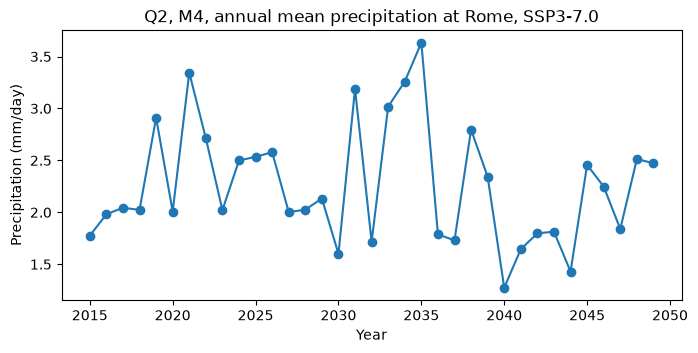

In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(annual.time.dt.year, annual, marker="o")
ax.set(xlabel="Year", ylabel="Precipitation (mm/day)", title="Q2, M4, annual mean precipitation at Rome, SSP3-7.0")
plt.show()

### Q3. My variable is not in Earth Data Hub. How do I get a time series at one place?

**Situation:** you need the temperature at 850 hPa (roughly 1.5 km above the ground) at Rome for July 2030, hour by hour. Earth Data Hub cubes have no pressure levels, so this variable is not there.

**Short answer:** M2. Add `ecmwf:feature` with the type `timeseries` and your point to the HDA search. The server reads the series next to the data and sends back only that.

**Why this route:** it works for any variable and level of any Digital Twin. 744 hourly values arrive as a few kilobytes, with the model's own values and no interpolation.

**Limitations:** the request goes through the order queue, so it takes seconds instead of opening a cube at once. You get the nearest native cell, not the exact point: Rome comes back as 41.81 N, 12.30 E. The answer is a CovJSON file, which you read with `json`. For decades of a variable that is in a cube, M4 (Q2) is faster.

In [9]:
t0 = time.time()
body = climate_body(["130"], ["850"], levtype="pl", resolution="standard", datetime="2030-07-01T00:00:00Z/2030-07-31T23:00:00Z",
                    hours=[f"{h:02d}00" for h in range(24)])  # temperature at 850 hPa, every hour of July 2030
body["query"]["ecmwf:feature"] = {"eq": {"type": "timeseries", "points": [[41.9028, 12.4964]], "time_axis": "date"}}
path = hda_order(body, headers)

In [10]:
t850 = covjson_series(path) - 273.15  # K to °C
report("Q3 | M2 timeseries", f"{t850.size} hourly values at {t850.attrs['lat']:.2f} N, {t850.attrs['lon']:.2f} E", size=path.stat().st_size, t0=t0)

[Q3 | M2 timeseries] 744 hourly values at 41.81 N, 12.30 E | 34 KB | 36 s


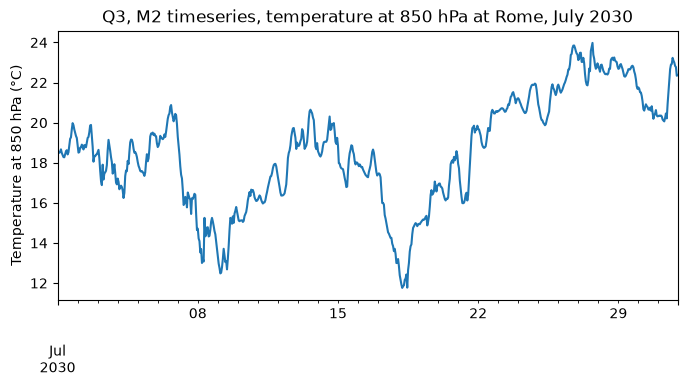

In [11]:
t850.plot(figsize=(8, 3.5), ylabel="Temperature at 850 hPa (°C)", title="Q3, M2 timeseries, temperature at 850 hPa at Rome, July 2030");

### Q4. How do I extract only my area, a profile or a route on the server?

**Situation:** you study the area around Brussels and need 2 m temperature for one hour, without downloading the global field. The same idea works for a vertical profile (one place, many heights of the atmosphere, for example above Rome) or a route (the cells along a path, for example a flight from Rome to Paris).

**Short answer:** M2. Add a shape to the HDA search: `bbox` or `intersects` with a polygon for an area, `ecmwf:feature` for a vertical profile or a route. HDA asks Polytope to cut the shape out next to the data.

**Why this route:** you receive a few native cells instead of millions of values. The download is a few kilobytes instead of megabytes, with the model's original values and no interpolation.

**Limitations:** the request still goes through the order queue, you get a CovJSON file instead of GRIB, and each request takes one shape. For a regular grid over the same box, see Q6.

Mind the order of the coordinates: STAC `bbox` and GeoJSON use [lon, lat], and `ecmwf:feature` uses [lat, lon].

**Bounding box.** `bbox` is [west, south, east, north].

In [12]:
t0 = time.time()
cities = {"Brussels": (4.35, 50.85), "Antwerp": (4.40, 51.22), "Ghent": (3.72, 51.05)}  # lon, lat, for the maps
body = climate_body(["167"], ["2"])  # 2 m temperature, 2030-07-15 12:00
body["bbox"] = [3.8, 50.5, 5.2, 51.3]
path = hda_order(body, headers)
lat, lon, t2m = covjson_points(path)
report("Q4 | M2 bbox", f"{t2m.size} native HEALPix cells", size=path.stat().st_size, t0=t0)

[Q4 | M2 bbox] 209 native HEALPix cells | 14 KB | 3 s


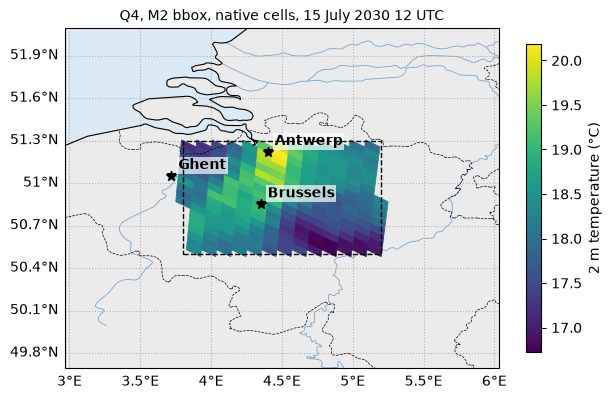

In [13]:
plot_cells(lat, lon, t2m - 273.15, 1024, "Q4, M2 bbox, native cells, 15 July 2030 12 UTC", "2 m temperature (°C)",
           pad=0.6, outline=[(3.8, 50.5), (5.2, 50.5), (5.2, 51.3), (3.8, 51.3), (3.8, 50.5)], marks=cities)

**Polygon.** `intersects` takes a GeoJSON Polygon, here an irregular polygon with five corners. A Point or a LineString in `intersects` returns an error: use `ecmwf:feature` for those.

In [14]:
t0 = time.time()
shape = [(3.9, 50.6), (4.9, 50.45), (5.3, 50.95), (4.7, 51.3), (3.8, 51.1), (3.9, 50.6)]  # lon, lat
body = climate_body(["167"], ["2"])
body["intersects"] = {"type": "Polygon", "coordinates": [shape]}
path = hda_order(body, headers)
lat, lon, t2m = covjson_points(path)
report("Q4 | M2 polygon", f"{t2m.size} native HEALPix cells inside the polygon", size=path.stat().st_size, t0=t0)

[Q4 | M2 polygon] 165 native HEALPix cells inside the polygon | 11 KB | 2 s


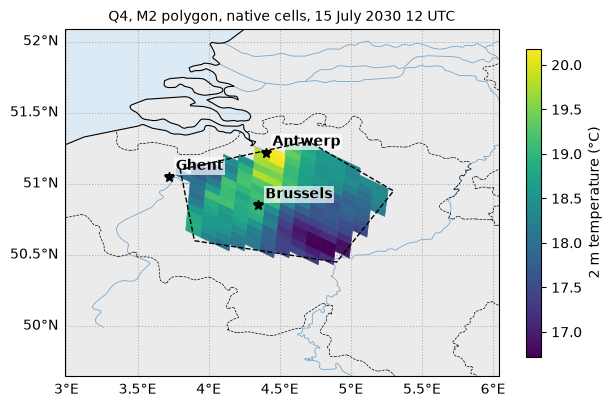

In [15]:
plot_cells(lat, lon, t2m - 273.15, 1024, "Q4, M2 polygon, native cells, 15 July 2030 12 UTC", "2 m temperature (°C)",
           pad=0.6, outline=shape, marks=cities)

**Vertical profile.** Temperature on the 19 pressure levels above Rome, with `verticalprofile`. A range of dates returns one profile per day, here 12 UTC of every day of 2030.

In [16]:
t0 = time.time()
levels = [1, 5, 10, 20, 30, 50, 70, 100, 150, 200, 250, 300, 400, 500, 600, 700, 850, 925, 1000]
body = climate_body(["130"], [str(level) for level in levels], levtype="pl", resolution="standard",
                    datetime="2030-01-01T12:00:00Z/2030-12-31T12:00:00Z")  # 12 UTC of every day of 2030
body["query"]["ecmwf:feature"] = {"eq": {"type": "verticalprofile", "points": [[41.9028, 12.4964]], "axes": "levelist"}}
path = hda_order(body, headers)
days = json.loads(path.read_text())["coverages"]  # one coverage per day
profiles = pd.DataFrame([d["ranges"]["t"]["values"] for d in days], columns=levels,
                        index=pd.to_datetime([d["domain"]["axes"]["t"]["values"][0] for d in days])) - 273.15  # K to °C
report("Q4 | M2 profile", f"{len(days)} daily profiles of {len(levels)} pressure levels above Rome", size=path.stat().st_size, t0=t0)

[Q4 | M2 profile] 365 daily profiles of 19 pressure levels above Rome | 412 KB | 29 s


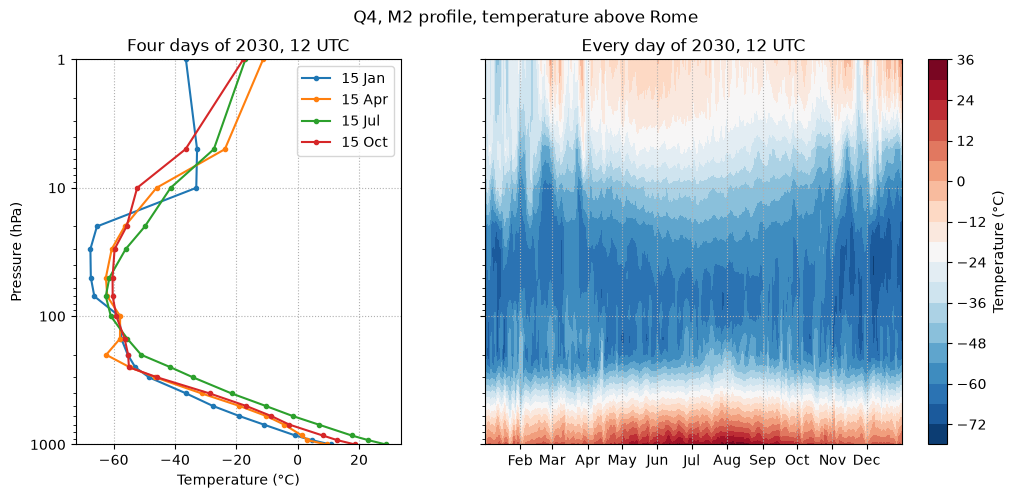

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5), sharey=True, gridspec_kw={"width_ratios": [1, 1.6]})
for day, name in {"01-15": "15 Jan", "04-15": "15 Apr", "07-15": "15 Jul", "10-15": "15 Oct"}.items():
    ax1.plot(profiles.loc[f"2030-{day} 12:00"], levels, marker="o", ms=3, label=name)
ax1.set(xlabel="Temperature (°C)", ylabel="Pressure (hPa)", title="Four days of 2030, 12 UTC")
ax1.legend()
image = ax2.contourf(profiles.index, levels, profiles.T, levels=20, cmap="RdBu_r")
fig.colorbar(image, ax=ax2, label="Temperature (°C)")
ax2.set(title="Every day of 2030, 12 UTC")
ax2.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax1.set(yscale="log")
ax1.yaxis.set_major_formatter("{x:g}")
ax1.invert_yaxis()
for ax in (ax1, ax2):
    ax.grid(ls=":")
fig.suptitle("Q4, M2 profile, temperature above Rome");

The same profile can be requested from Polytope directly. Polytope has its own token, which you get with the same DESP user and password.

In [18]:
t0 = time.time()
request = {**POLYTOPE_CLIMATE, "resolution": "standard", "levtype": "pl", "param": "130",
           "feature": {"type": "verticalprofile", "points": [[41.9028, 12.4964]], "axes": "levelist", "range": {"start": 0, "end": 1000}}}
answer = polytope_retrieve(request, polytope_headers(user, password))
profile_polytope = json.loads(answer)["coverages"][0]["ranges"]["t"]["values"]  # K
same = np.allclose(profiles.loc["2030-07-15 12:00"] + 273.15, profile_polytope)
report("Q4 | M2 Polytope", f"same profile as HDA on 15 July: {same}", size=len(answer), t0=t0)

[Q4 | M2 Polytope] same profile as HDA on 15 July: True | 2 KB | 21 s


**Route.** `trajectory` follows a line through your points, here Rome, Milan and Paris, and returns the cells along it. `inflation` widens the line into a corridor.

In [19]:
t0 = time.time()
route = {"Rome": [41.9028, 12.4964], "Milan": [45.4642, 9.19], "Paris": [48.8566, 2.3522]}  # [lat, lon]
body = climate_body(["165"], ["10"], resolution="standard")  # 10 m U wind
body["query"]["ecmwf:feature"] = {"eq": {"type": "trajectory", "inflation": 0.5, "axes": ["latitude", "longitude"],
                                          "points": list(route.values())}}
path = hda_order(body, headers)
lat, lon, u10 = covjson_points(path)
report("Q4 | M2 route", f"{u10.size} cells along Rome, Milan and Paris", size=path.stat().st_size, t0=t0)

[Q4 | M2 route] 44 cells along Rome, Milan and Paris | 4 KB | 11 s


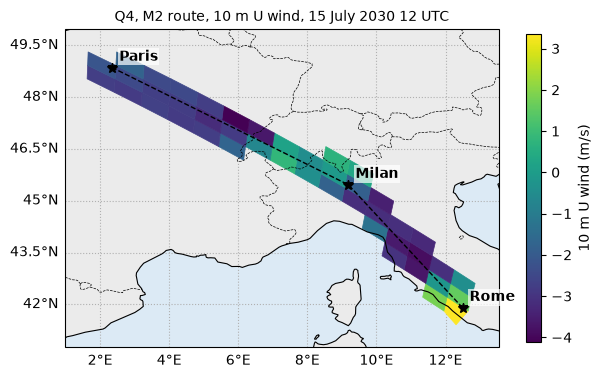

In [20]:
stops = {name: (lon, lat) for name, (lat, lon) in route.items()}  # [lon, lat] for the map
plot_cells(lat, lon, u10, 128, "Q4, M2 route, 10 m U wind, 15 July 2030 12 UTC", "10 m U wind (m/s)",
           outline=list(stops.values()), marks=stops)

### Q5. How do I select my own cells on the native HEALPix grid?

**Situation:** you want the 10 m wind speed over Zealand and Scania, the area around Copenhagen. Speed needs two variables, u and v, and you want to pick the cells yourself, maybe for several areas from one download.

**Short answer:** order the global GRIB once (M1) and select the cells on your computer. The cell number of a HEALPix grid follows from latitude and longitude, so you can use a NumPy mask or `healpy.query_polygon`. Both give the same cells.

**Why this route:** one download serves any number of areas, and you can compute with the full field. The cells are the model's own, the same ones that the server returns for a box in Q4.

**Limitations:** this is the heaviest download (MB for u and v), and you need `healpy` and `earthkit-data`. For one area, Q4 is lighter.

In [21]:
t0 = time.time()
body = climate_body(["165", "166"], ["10"])  # 10 m wind, u and v
path = hda_order(body, headers)
u, v = [field.to_numpy() for field in ekd.from_source("file", str(path)).to_fieldlist()]
speed = (u ** 2 + v ** 2) ** 0.5
report("Q5 | M1 global GRIB", f"{speed.size:,} native HEALPix cells | mean wind {speed.mean():.1f} m/s", size=path.stat().st_size, t0=t0)

[Q5 | M1 global GRIB] 12,582,912 native HEALPix cells | mean wind 6.5 m/s | 55.5 MB | 21 s


In [22]:
t0 = time.time()
box = [10.5, 54.8, 14.5, 56.5]  # west, south, east, north, Zealand and Scania around Copenhagen
nside = hp.npix2nside(speed.size)
lon, lat = hp.pix2ang(nside, np.arange(speed.size), nest=True, lonlat=True)  # the Climate DT grid is nested
lon = (lon + 180) % 360 - 180  # 0..360 to -180..180
mask = (lon >= box[0]) & (lon <= box[2]) & (lat >= box[1]) & (lat <= box[3])
report("Q5 | numpy mask", f"{mask.sum()} cells in the box", t0=t0)

[Q5 | numpy mask] 1186 cells in the box | 1 s


In [23]:
t0 = time.time()
corners = hp.ang2vec([box[0], box[2], box[2], box[0]], [box[1], box[1], box[3], box[3]], lonlat=True)  # lon, lat of the four corners
cells = hp.query_polygon(nside, corners, nest=True)
report("Q5 | healpy", f"{cells.size} cells | same cells as the mask: {set(cells) == set(mask.nonzero()[0])}", t0=t0)

[Q5 | healpy] 1186 cells | same cells as the mask: True | 0 s


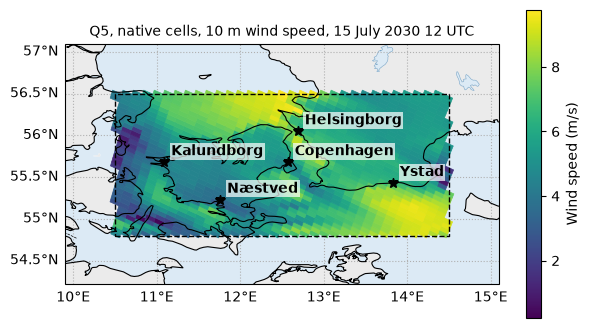

In [9]:
plot_cells(lat[mask], lon[mask], speed[mask], nside, "Q5, native cells, 10 m wind speed, 15 July 2030 12 UTC", "Wind speed (m/s)", pad=0.15,
           outline=[(box[0], box[1]), (box[2], box[1]), (box[2], box[3]), (box[0], box[3]), (box[0], box[1])],
           marks={"Copenhagen": (12.57, 55.68), "Helsingborg": (12.69, 56.05), "Kalundborg": (11.09, 55.68), "Næstved": (11.76, 55.23), "Ystad": (13.83, 55.43)})

### Q6. How do I get a regular grid at my own resolution?

**Situation:** you need the 10 m wind over the Iberian Peninsula and the sea around it on a regular 0.25° grid, ready for a map or to combine with other gridded data.

**Short answer:** M3. Send the request to Polytope with `grid` and `area`. The server interpolates, crops and sends back a small GRIB.

**Why this route:** it is the only server-side route that returns an area on a regular grid. You choose the resolution, and any variable works.

**Limitations:** Polytope has its own address and token (the DESP user and password are the same), and the server does the interpolation, so you do not see how. HDA also has `ecmwf:grid`, but it returns the whole globe and cannot be combined with a shape. `area` is written as north/west/south/east.

In [25]:
t0 = time.time()
request = {**POLYTOPE_CLIMATE, "resolution": "high", "levtype": "sfc", "param": ["165", "166"],  # 10 m wind, u and v
           "grid": "0.25/0.25", "area": "46/-12/34/6"}  # north, west, south, east
answer = polytope_retrieve(request, polytope_headers(user, password))
wind = ekd.from_source("memory", answer).to_xarray()
speed = (wind["10u"] ** 2 + wind["10v"] ** 2) ** 0.5
report("Q6 | M3 grid + area", f"{speed.latitude.size} x {speed.longitude.size} cells of 0.25 degrees", size=len(answer), t0=t0)

[Q6 | M3 grid + area] 49 x 73 cells of 0.25 degrees | 20 KB | 20 s


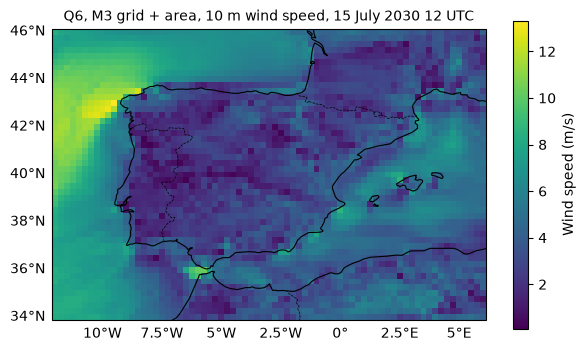

In [26]:
plot_grid(speed, "Q6, M3 grid + area, 10 m wind speed, 15 July 2030 12 UTC", "Wind speed (m/s)")

### Q7. How do I compute statistics over a large region and many years?

**Situation:** you want the average summer (June to August) 2 m temperature over the whole Iberian Peninsula, for every year until 2049.

**Short answer:** M4 with Dask. Open the Earth Data Hub cube lazily, select the region and let Dask read and average the chunks in parallel.

**Why this route:** there is no queue and no download step, and the cube is read only where you ask. For this question we use the `HOURLY_STANDARD` cube, coarser than the one in Q2, so a large region needs few reads.

**Limitations:** the grid is coarse, so local detail is lost, and the limits of Q2 apply (Climate DT generation 2 only, fixed list of variables). It takes a minute or two, because every hourly step of the summers is read. If your variable is not in an Earth Data Hub cube, request the region on a regular grid with M3 (Q6) for each time you need, or work with the native fields (Q5). For the Extremes DT, see Q8 and Q9.

In [27]:
t0 = time.time()
cube = open_cube("EO.ECMWF.DAT.D1.DT_CLIMATE.G2.SSP3-7.0_IFS-NEMO_HOURLY_STANDARD", headers)
iberia = cube["t2m"].sel(latitude=slice(36, 44), longitude=slice(-10, 3.5))  # latitude runs from south to north in this cube
report("Q7 | M4 open", f"lazy region of {iberia.latitude.size} x {iberia.longitude.size} cells and {iberia.sizes['time']:,} hourly steps | at most {iberia.data.npartitions} chunk reads", t0=t0)

[Q7 | M4 open] lazy region of 23 x 38 cells and 306,816 hourly steps | at most 428 chunk reads | 7 s


In [28]:
t0 = time.time()
summer = iberia.isel(time=iberia.time.dt.month.isin([6, 7, 8]))  # June, July and August
yearly = retry(lambda: summer.groupby("time.year").mean().compute()) - 273.15  # one summer-mean map per year, in °C
report("Q7 | M4 + Dask", f"{yearly.year.size} summer means over {yearly.latitude.size * yearly.longitude.size} cells", t0=t0)

[Q7 | M4 + Dask] 35 summer means over 874 cells | 43 s


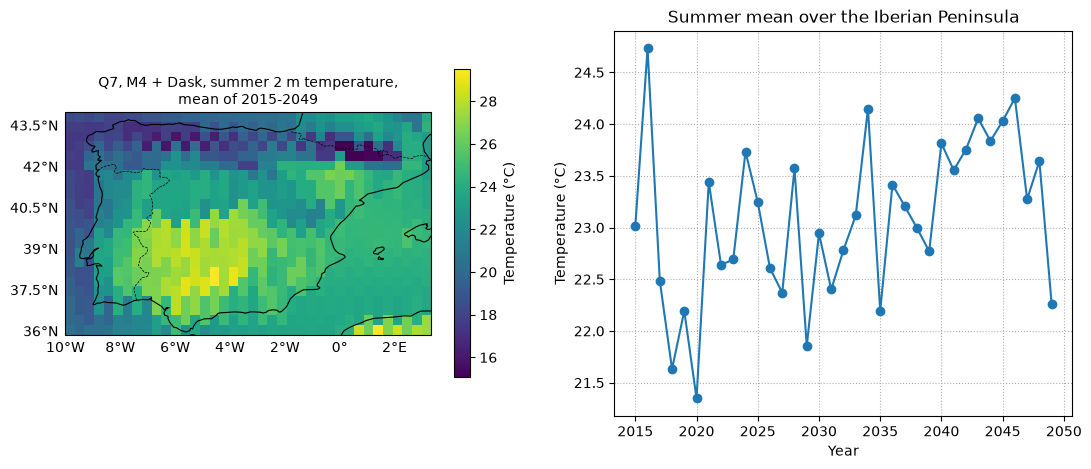

In [29]:
fig = plt.figure(figsize=(13, 5))
plot_grid(yearly.mean("year"), "Q7, M4 + Dask, summer 2 m temperature,\nmean of 2015-2049", "Temperature (°C)", ax=fig.add_subplot(1, 2, 1, projection=ccrs.PlateCarree()))
ax = fig.add_subplot(1, 2, 2)
yearly.weighted(np.cos(np.deg2rad(yearly.latitude))).mean(("latitude", "longitude")).plot(ax=ax, marker="o")
ax.set(title="Summer mean over the Iberian Peninsula", xlabel="Year", ylabel="Temperature (°C)")
ax.grid(ls=":")

### Q8. How do I get the global field?


**Situation:** you want the 10 m wind gust forecast of the Extremes DT for the whole globe, for one forecast date, to look for storms anywhere.

**Short answer:** M3. Ask Polytope for a regular grid of 0.25 degrees over the whole globe, with `grid` and `area` as in Q6, but on the Extremes DT. This Digital Twin is served from the LUMI address. The Extremes DT keeps about 30 days, and the valid dates are in the queryables of the collection.

**Why this route:** you get the whole globe in a small GRIB file, already on a regular grid that most tools can plot, and you do not need to regrid it on your computer.

**Limitations:** the server interpolates the model's native grid (an octahedral reduced Gaussian grid, O2560, with 26 million points), so the values are not exactly the ones the model wrote. If you need the native values, order the full field with M1, as in Q5 for the Climate DT. The request can take a minute or two.

In [ ]:
t0 = time.time()
_, day = extremes_body("228029")  # only the date of the latest forecast is needed
request = {"class": "d1", "dataset": "extremes-dt", "expver": "0001", "stream": "oper", "type": "fc", "levtype": "sfc",
           "param": "228029", "date": day, "time": "0000", "step": "6",  # 10 m wind gust
           "grid": "0.25/0.25", "area": "90/-180/-90/180"}  # north, west, south, east: the whole globe
answer = polytope_retrieve(request, polytope_headers(user, password), address=LUMI)
gust = ekd.from_source("memory", answer).to_xarray()["i10fg"]
report("Q8 | M3 global", f"forecast of {day}, +6 h | {gust.latitude.size} x {gust.longitude.size} cells of 0.25 degrees | maximum gust {float(gust.max()):.0f} m/s", size=len(answer), t0=t0)

[Q8 | M3 global] forecast of 20261115, +6 h | 721 x 1440 cells of 0.25 degrees | maximum gust 38 m/s | 2.5 MB | 49 s


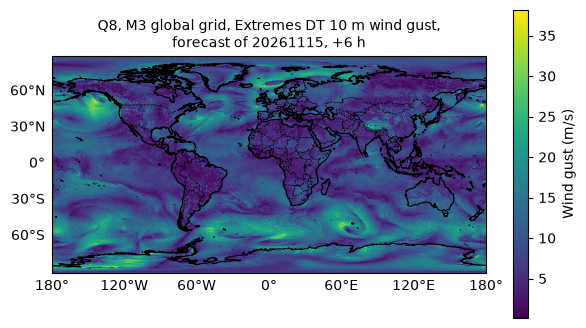

In [ ]:
plot_grid(gust, f"Q8, M3 global grid, Extremes DT 10 m wind gust,\nforecast of {day}, +6 h", "Wind gust (m/s)")

## By Digital Twin

### Q9. How do I get a recent Extremes DT forecast for my area?

**Situation:** you want the 2 m temperature forecast of the Extremes DT over the southern Netherlands, for the latest forecast, without downloading the global field.

**Short answer:** M2. Use the same `bbox` as in Q4, now on the Extremes DT collection, with the date of a recent forecast. HDA passes the request to Polytope, which serves the Extremes DT.

**Why this route:** the Extremes DT has a new forecast every day and keeps about 30 days. A box returns only your points, with the model's own values, instead of the whole globe.

**Limitations:** only recent dates are available, so read them from the queryables as in Q8. The Extremes DT grid is not HEALPix, so the points have no cell shape to draw and `healpy` does not apply. For a large region, the global field of Q8 is the alternative.

In [33]:
t0 = time.time()
body, day = extremes_body("167")  # 2 m temperature, latest forecast
body["bbox"] = [3.3, 51.2, 4.9, 52.3]  # southern Netherlands
path = hda_order(body, headers)
lat, lon, t2m = covjson_points(path)
report("Q9 | M2 bbox", f"{t2m.size} native points | forecast of {day}, +6 h", size=path.stat().st_size, t0=t0)

[Q9 | M2 bbox] 621 native points | forecast of 20261110, +6 h | 37 KB | 4 s


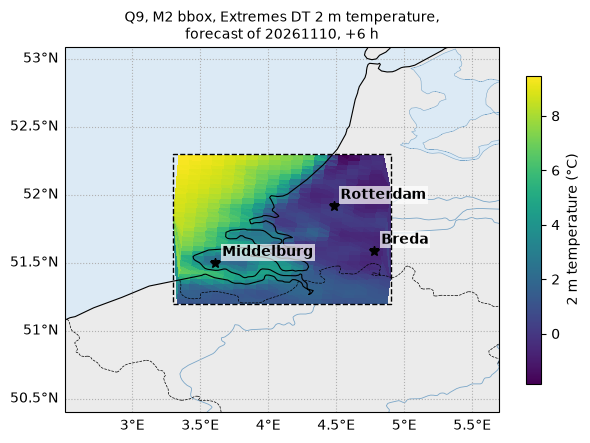

In [34]:
ax = base_map([lon.min(), lon.max(), lat.min(), lat.max()], pad=0.5, outline=[(3.3, 51.2), (4.9, 51.2), (4.9, 52.3), (3.3, 52.3), (3.3, 51.2)],
              marks={"Rotterdam": (4.48, 51.92), "Middelburg": (3.61, 51.50), "Breda": (4.78, 51.59)})
points = ax.tripcolor(lon, lat, t2m - 273.15, transform=ccrs.PlateCarree(), zorder=2)
plt.colorbar(points, ax=ax, label="2 m temperature (°C)", shrink=0.8)
ax.set_title(f"Q9, M2 bbox, Extremes DT 2 m temperature,\nforecast of {day}, +6 h", fontsize=10);

### Q10. How do I get storylines, generation 1 and nextGEMS?

**Situation:** you want to compare the temperature at Rome in a storyline of the past with one in a world 2 °C warmer, and see the same kind of data in generation 1 and in nextGEMS.

**Short answer:** M2, with the same `timeseries` request as in Q3 and a different collection. Storylines, generation 1 and nextGEMS are all collections in HDA.

**Why this route:** Earth Data Hub has cubes for generation 2 only, and M2 works for every collection.

**Limitations:** the request changes a little between families. Generation 2 needs `levelist` for surface variables and has a monthly stream (`clmn`). Generation 1 and nextGEMS do not accept `levelist` with surface variables, and here we use their hourly data. The generation 1 ICON collection does not accept the `resolution` filter either. Each family covers its own period, so read the dates from the queryables.

In [35]:
t0 = time.time()
story = "EO.ECMWF.DAT.D1.DT_CLIMATE.G2.STORY-NUDGING_{}_IFS-FESOM.R1"
monthly = {}
for kind in ["HIST", "TPLUS2.0K"]:  # the storyline of the past and the storyline of a world 2 K warmer
    body = {"collections": [story.format(kind)],
            "query": {"ecmwf:resolution": {"eq": "high"}, "ecmwf:stream": {"eq": "clmn"}, "ecmwf:levtype": {"eq": "sfc"},
                      "ecmwf:levelist": {"eq": ["2"]}, "ecmwf:param": {"eq": ["228004"]}, "ecmwf:year": {"eq": ["2020"]},
                      "ecmwf:month": {"eq": [str(m) for m in range(1, 13)]},
                      "ecmwf:feature": {"eq": {"type": "timeseries", "points": [[41.9028, 12.4964]], "time_axis": "month"}}}}
    monthly[kind] = covjson_series(hda_order(body, headers)) - 273.15  # K to °C
report("Q10 | M2 storylines G2", f"{len(monthly['HIST'])} monthly means in 2020 for each of the 2 storylines", t0=t0)

[Q10 | M2 storylines G2] 12 monthly means in 2020 for each of the 2 storylines | 5 s


In [36]:
def july(collection, year, resolution="standard"):
    """Daily mean 2 m temperature at Rome in July. Generation 1 and nextGEMS do not take levelist."""
    query = {"ecmwf:levtype": {"eq": "sfc"}, "ecmwf:param": {"eq": ["167"]}, "ecmwf:time": {"eq": [f"{h:02d}00" for h in range(24)]},
             "ecmwf:feature": {"eq": {"type": "timeseries", "points": [[41.9028, 12.4964]], "time_axis": "date"}}}
    if resolution:
        query["ecmwf:resolution"] = {"eq": resolution}
    body = {"collections": [collection], "datetime": f"{year}-07-01T00:00:00Z/{year}-07-31T23:00:00Z", "query": query}
    return (covjson_series(hda_order(body, headers)) - 273.15).resample("D").mean()  # K to °C


t0 = time.time()
g1 = {kind: july(f"EO.ECMWF.DAT.D1.DT_CLIMATE.G1.STORY-NUDGING_{kind}_IFS-FESOM.R1", 2020) for kind in ["HIST", "TPLUS2.0K"]}
historical = {"nextGEMS": july("EO.ECMWF.DAT.NG.DT_CLIMATE.G1.CMIP6_HIST_IFS-FESOM.R1", 2010),
              "ICON, generation 1": july("EO.ECMWF.DAT.D1.DT_CLIMATE.G1.CMIP6_HIST_ICON.R1", 2010, resolution=None)}
report("Q10 | M2 G1 and nextGEMS", f"{len(g1['HIST'])} daily means in July for each of the 4 series", t0=t0)

[Q10 | M2 G1 and nextGEMS] 31 daily means in July for each of the 4 series | 19 s


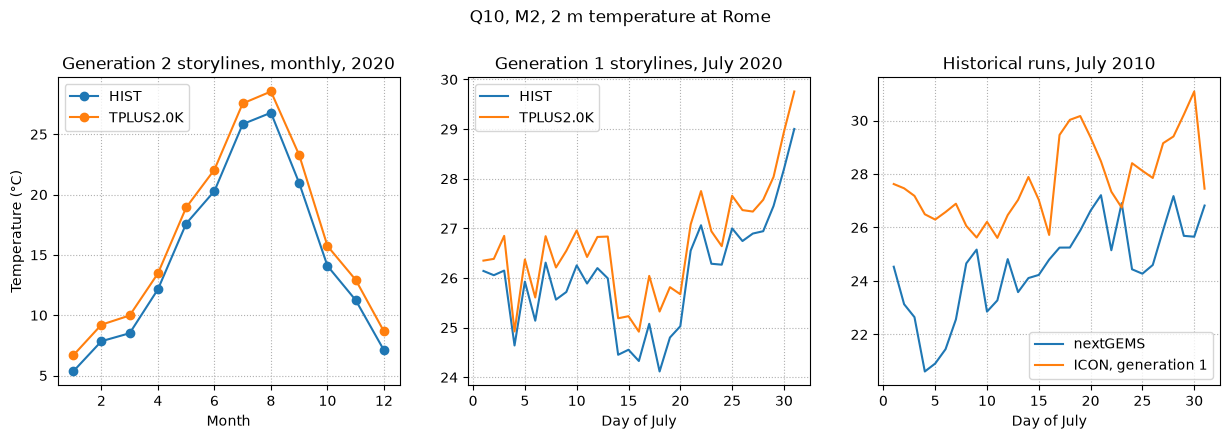

In [37]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for kind, values in monthly.items():
    axes[0].plot(values.index.month, values, marker="o", label=kind)
axes[0].set(title="Generation 2 storylines, monthly, 2020", xlabel="Month")
for kind, values in g1.items():
    axes[1].plot(values.index.day, values, label=kind)
axes[1].set(title="Generation 1 storylines, July 2020", xlabel="Day of July")
for name, values in historical.items():
    axes[2].plot(values.index.day, values, label=name)
axes[2].set(title="Historical runs, July 2010", xlabel="Day of July")
for ax in axes:
    ax.grid(ls=":")
    ax.legend()
axes[0].set_ylabel("Temperature (°C)")
fig.suptitle("Q10, M2, 2 m temperature at Rome", y=1.05);

### Q11. How do I get the On-Demand Extremes DT?

**Situation:** you want the 2 m temperature of an On-Demand Extremes DT run, which covers a limited domain at high resolution.

**Short answer:** Polytope direct. The request looks like the one in Q6, but it goes to the LUMI address with `dataset` set to `on-demand-extremes-dt` and a `georef` that identifies the domain.

**Why this route:** it is the way we found to reach this data. We did not find an HDA collection for it.

**Limitations:** Point and area extraction is enabled for one run only, and in our tests a time series returned the same point for two different places, so we show the full field. The grid is Lambert, which needs `eccodes` to decode. `earthkit-data` does it for you.

In [38]:
t0 = time.time()
request = {"class": "d1", "dataset": "on-demand-extremes-dt", "expver": "0099", "stream": "oper", "type": "fc", "date": "20250926",
           "time": "0000", "levtype": "sfc", "param": "167", "georef": "gcgkrb", "step": "1", "resolution": "high"}
answer = polytope_retrieve(request, polytope_headers(user, password), address=LUMI)
field = ekd.from_source("memory", answer).to_fieldlist()[0]
t2m = field.to_numpy().reshape(field.shape)
lat, lon = (a.reshape(field.shape) for a in (field.geography.latitudes(), field.geography.longitudes()))
lon = (lon + 180) % 360 - 180  # 0..360 to -180..180
report("Q11 | Polytope On-Demand", f"{t2m.size:,} points on a {field.metadata('gridType')} grid", size=len(answer), t0=t0)

[Q11 | Polytope On-Demand] 2,217,121 points on a lambert_lam grid | 2.7 MB | 6 s


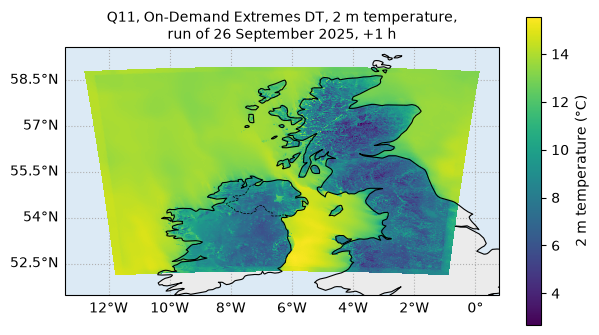

In [39]:
ax = base_map([lon.min(), lon.max(), lat.min(), lat.max()], pad=0.05)
image = ax.pcolormesh(lon[::3, ::3], lat[::3, ::3], t2m[::3, ::3] - 273.15, transform=ccrs.PlateCarree(), zorder=2, shading="auto")
plt.colorbar(image, ax=ax, label="2 m temperature (°C)", shrink=0.8)
ax.set_title("Q11, On-Demand Extremes DT, 2 m temperature,\nrun of 26 September 2025, +1 h", fontsize=10);

## Wrap-up

### Q12. Which format do I get, and how do I open it?

**Situation:** you have tried several routes and want to know what each one returns and how to read it.

**Short answer:** the route decides the format.

| Mechanism | You ask | You get | Open it with |
|---|---|---|---|
| M1 | HDA order | GRIB, global field | `earthkit-data`, then `to_numpy()` or `to_xarray()` |
| M2 | HDA or Polytope, plus a shape | CovJSON, only your cells | `json` |
| M3 | Polytope, plus `grid` and `area` | small GRIB, regular grid | `earthkit-data`, then `to_xarray()` |
| M4 | Earth Data Hub, found through HDA | Zarr cube, read lazily | `xarray`, lazy, with Dask |

**Why a comparison:** the cells below send the same request through M1 to M4: the 2 m dewpoint temperature of the ICON model over a large area around Berlin, at one hour. The four answers are drawn with the same colour scale.

**Limitations:** M1 and M2 give the model's own cells, so they agree. M3 and M4 are on a regular grid, so the values differ a little because of the interpolation. Polytope has more than one address, and the model decides which one: ICON is on the LUMI address.

In [40]:
t0 = time.time()
box = [11.5, 51.7, 15.2, 53.3]  # west, south, east, north, a large area around Berlin
icon = "EO.ECMWF.DAT.D1.DT_CLIMATE.G2.PROJECTIONS_SSP3-7.0_ICON.R1"  # the ICON model of the Climate DT, generation 2
body = {**climate_body(["168"], ["2"]), "collections": [icon]}  # 2 m dewpoint temperature, 2030-07-15 12:00
# M1: order the global field and cut the box on your computer
field = ekd.from_source("file", str(hda_order(body, headers))).to_fieldlist()[0].to_numpy()
nside = hp.npix2nside(field.size)
corners = hp.ang2vec([box[0], box[2], box[2], box[0]], [box[1], box[1], box[3], box[3]], lonlat=True)
cells = hp.query_polygon(nside, corners, nest=True)
lon1, lat1 = hp.pix2ang(nside, cells, nest=True, lonlat=True)
m1 = field[cells]
# M2: the server cuts the box
lat2, lon2, m2 = covjson_points(hda_order({**body, "bbox": box}, headers))
# M3: Polytope, regular grid of 0.1 degrees
request = {**POLYTOPE_CLIMATE, "model": "ICON", "resolution": "high", "levtype": "sfc", "param": "168", "grid": "0.1/0.1", "area": f"{box[3]}/{box[0]}/{box[1]}/{box[2]}"}
m3 = ekd.from_source("memory", polytope_retrieve(request, polytope_headers(user, password), address=LUMI)).to_xarray().to_array()[0]
# M4: Earth Data Hub cube
cube = open_cube("EO.ECMWF.DAT.D1.DT_CLIMATE.G2.SSP3-7.0_ICON_HOURLY_HIGH_MAPS", headers)
m4 = retry(cube["d2m"].sel(time="2030-07-15T12:00").sel(latitude=slice(box[1], box[3]), longitude=slice(box[0], box[2])).load)
report("Q12 | four routes", f"M1 {m1.size} cells | M2 {m2.size} cells | M3 {m3.size} points | M4 {m4.size} points", t0=t0)

[Q12 | four routes] M1 1092 cells | M2 1093 cells | M3 646 points | M4 3108 points | 29 s


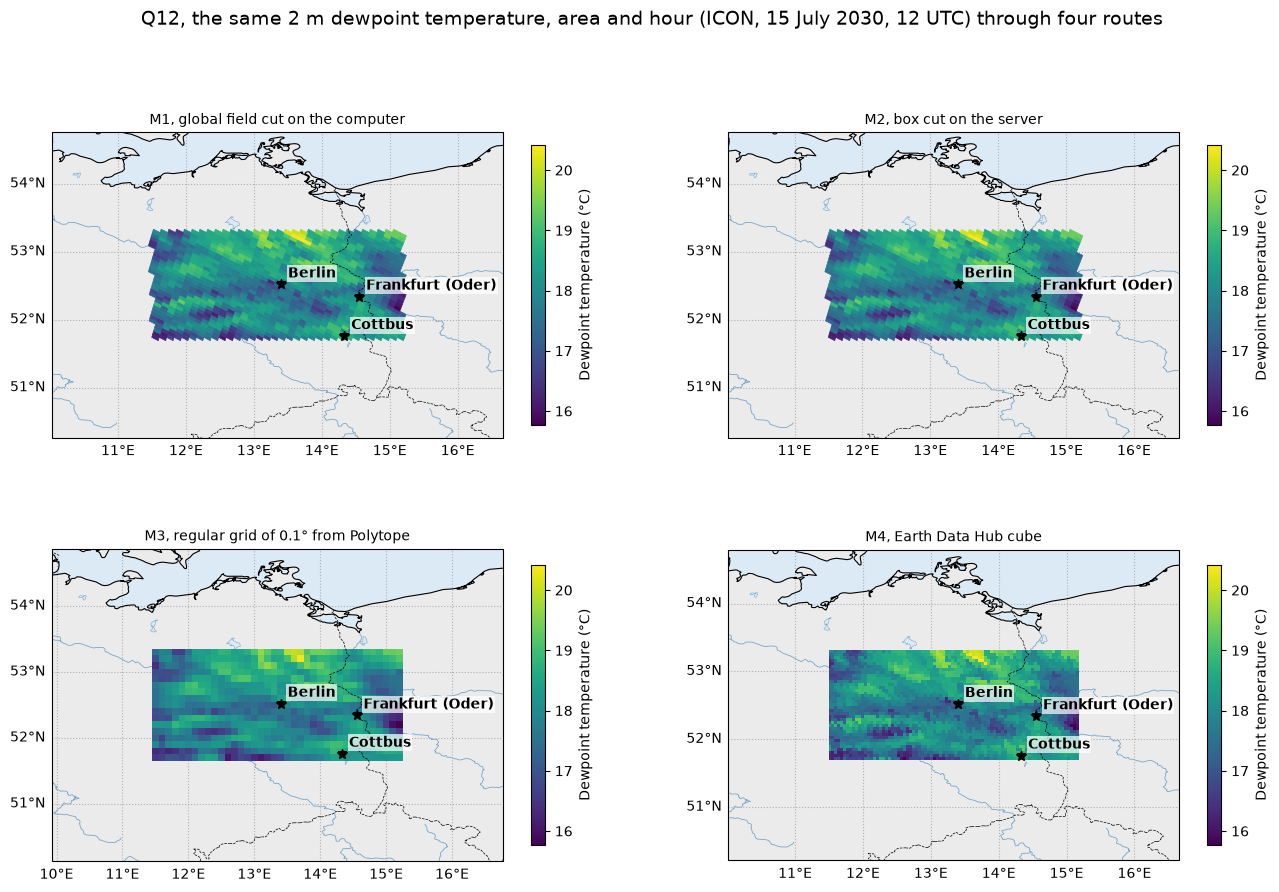

In [41]:
cities = {"Berlin": (13.40, 52.52), "Cottbus": (14.33, 51.76), "Frankfurt (Oder)": (14.55, 52.34)}  # lon, lat
values = (m1, m2, m3.values, m4.values)
scale = {"vmin": min(v.min() for v in values) - 273.15, "vmax": max(v.max() for v in values) - 273.15, "pad": 0.4, "marks": cities}  # same colours in the four maps
fig, axes = plt.subplots(2, 2, figsize=(16, 10), subplot_kw={"projection": ccrs.PlateCarree()})
plot_cells(lat1, lon1, m1 - 273.15, nside, "M1, global field cut on the computer", "Dewpoint temperature (°C)", ax=axes[0, 0], **scale)
plot_cells(lat2, lon2, m2 - 273.15, nside, "M2, box cut on the server", "Dewpoint temperature (°C)", ax=axes[0, 1], **scale)
plot_grid(m3 - 273.15, "M3, regular grid of 0.1° from Polytope", "Dewpoint temperature (°C)", ax=axes[1, 0], **scale)
plot_grid(m4 - 273.15, "M4, Earth Data Hub cube", "Dewpoint temperature (°C)", ax=axes[1, 1], **scale)
fig.suptitle("Q12, the same 2 m dewpoint temperature, area and hour (ICON, 15 July 2030, 12 UTC) through four routes", fontsize=14);

The diagram shows how to choose a route. Start from the Digital Twin you need and follow the arrows. The colours show the shape of the result: blue is the native full field, orange is a piece cut on the server, green is a ready-to-use cube and grey is the On-Demand Extremes DT, which has its own route.

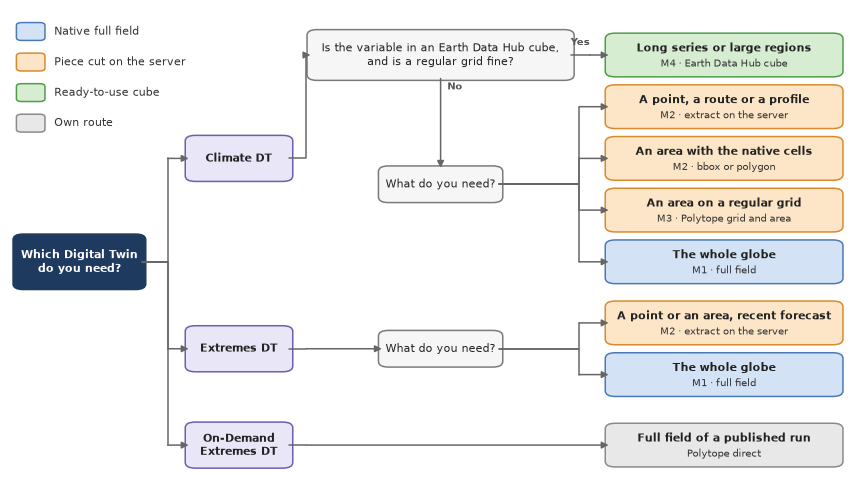

## Summary

This notebook showed four ways to reach the DestinE Digital Twins and the situations where each one fits. Use M1 for the whole globe on the model's own grid. Use M2 to cut a point, a box, a polygon, a vertical profile or a route on the server. Use M3 for an area on a regular grid that you choose. Use M4 for long time series and statistics over large regions of the Climate DT. The On-Demand Extremes DT is reached through Polytope directly. The right choice depends on the shape of the result you need and on the Digital Twin it comes from.

## Resources and references

- [DestinE Data Lake documentation: Harmonized Data Access](https://destine-data-lake-docs.data.destination-earth.eu/en/latest/dedl-discovery-and-data-access/Use-of-Harmonized-Data-Access/Use-of-Harmonized-Data-Access.html)
- [DestinE Data Portfolio](https://data.destination-earth.eu/data-portfolio)
- [Earth Data Hub catalogue](https://earthdatahub.destine.eu/catalogue)
- [Climate Change Adaptation Digital Twin (Climate DT)](https://destine.ecmwf.int/climate-change-adaptation-digital-twin-climate-dt/)
- [Polytope examples](https://github.com/destination-earth-digital-twins/polytope-examples)
- [DestinE access policy](https://platform.destine.eu/support-pages/access-policy/)
- [earthkit-geo](https://github.com/ecmwf/earthkit-geo)